# Isothermal 0D Master Equation Simulation
### Import libraries

In [1]:
import os
import sys
import pickle
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm.notebook import tqdm

Visualization libraries

In [2]:
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
# %matplotlib qt
COLORS = mpl.rcParams['axes.prop_cycle'].by_key()['color']

Global paths

In [3]:
# Current Working Directory
CWD = os.getcwd()
# WORKSPACE
WORKSPACE = os.environ['WORKSPACE_PATH']
# SurQCT
SurQCT = WORKSPACE + '/ML/PyCOMET/pycomet/examples/SurQCT/'
sys.path.append(os.path.abspath(SurQCT))

In [4]:
case_suffix = '/O3_UMN/Inel/configs/config.06/run.01/'

# Output directory
out_dir = CWD + '/../Output/MasterEquation/'
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

### Initializing Run

In [5]:
SystemName = 'O3_UMN'
ProcBool   = [0,1,0,0]
ProcCode   = "_".join(map(str, ProcBool))
TTranVec   = [1500, 5000, 10000, 20000]
RunSuffix  = '/Inel/configs/config.06/run.01/'

In [6]:
PathToCase = {
    'QCT':        f'/QCT/{SystemName}/',
    'SurQCT-Ref': f'/SurQCT/{SystemName}/Inel/run.ref/',
#     'SurQCT.32':  f'/SurQCT/{SystemName}/Inel/configs/config.03/run.02/',
    'SurQCT-C03':  f'/SurQCT/{SystemName}/Inel/configs/config.03/run.03/',
#     'SurQCT.61':  f'/SurQCT/{SystemName}/Inel/configs/config.06/run.01/',
#     'SurQCT.62':  f'/SurQCT/{SystemName}/Inel/configs/config.06/run.02/',
    'SurQCT-C06':  f'/SurQCT/{SystemName}/Inel/configs/config.06/run.03/',
#     'SurQCT.r2':  f'/SurQCT/{SystemName}/Inel/configs/config.ref/run.02/'
}
Data       = {k: {} for k in PathToCase.keys()}

In [7]:
out_dir = out_dir + ProcCode
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

Initializing chemical system

In [8]:
from surqct.src.chemical_systems import chemical_systems as chem_sys

System = chem_sys.get_system(SystemName, ProcBool)
# Initializing molecules
for Mol in System.Molecules:
    Mol.read_diatdata()
ME = System.MasterEquation

### Reading Master Equation Solution Files

In [9]:
for iTemp in tqdm(range(len(TTranVec))):

    Temp = int(TTranVec[iTemp])
    
    print(f'\nReading data for temperature T = {Temp} K')
    for k in Data.keys():
        print(f'>> Reading 0D ME solution for {k}')
        Data[k][Temp]        = {}
        PathToCase_k         = PathToCase[k] + f'/T{str(Temp)}K/{ProcCode}/output_box/'
        Data[k][Temp]['box'] = ME.read_box(PathToCase_k)
        Data[k][Temp]['pop'] = ME.read_popevolution(PathToCase_k, TimeInstants=len(Data[k][Temp]['box']))

#     QCT[Temp] = {}
#     SurQCT[Temp] = {}
#     SurQCTRef[Temp] = {}

#     # QCT
#         print(f'\nReading    QCT 0D ME solution at temperature T = {Temp} K')
#         PathToCase             = f'/QCT/{SystemName}/T{str(Temp)}K/{ProcCode}/output_box/'
#         QCT[Temp]['box']       = ME.read_box(PathToCase)
#         QCT[Temp]['pop']       = ME.read_popevolution(PathToCase, TimeInstants=len(QCT[Temp]['box']))

#     # SurQCT
#     print(f'Reading SurQCT 0D ME solution at temperature T = {Temp} K')
#     PathToCase             = f'/SurQCT/{SystemName}/{RunSuffix}/T{str(Temp)}K/{ProcCode}/output_box/'
#     SurQCT[Temp]['box']    = ME.read_box(PathToCase)
#     SurQCT[Temp]['pop']    = ME.read_popevolution(PathToCase, TimeInstants=len(SurQCT[Temp]['box']))

#     # SurQCT-Ref
#     print(f'Reading SurQCT-Ref 0D ME solution at temperature T = {Temp} K')
#     PathToCase             = f'/SurQCT/{SystemName}/Inel/run.ref/T{str(Temp)}K/{ProcCode}/output_box/'
#     SurQCTRef[Temp]['box'] = ME.read_box(PathToCase)
#     SurQCTRef[Temp]['pop'] = ME.read_popevolution(PathToCase, TimeInstants=len(SurQCTRef[Temp]['box']))


  0%|          | 0/4 [00:00<?, ?it/s]


Reading data for temperature T = 1500 K
>> Reading 0D ME solution for QCT
>> Reading 0D ME solution for SurQCT.61
>> Reading 0D ME solution for SurQCT.62
>> Reading 0D ME solution for SurQCT.63
>> Reading 0D ME solution for SurQCT.32
>> Reading 0D ME solution for SurQCT.33
>> Reading 0D ME solution for SurQCT.r2

Reading data for temperature T = 5000 K
>> Reading 0D ME solution for QCT
>> Reading 0D ME solution for SurQCT.61
>> Reading 0D ME solution for SurQCT.62
>> Reading 0D ME solution for SurQCT.63
>> Reading 0D ME solution for SurQCT.32
>> Reading 0D ME solution for SurQCT.33
>> Reading 0D ME solution for SurQCT.r2

Reading data for temperature T = 10000 K
>> Reading 0D ME solution for QCT
>> Reading 0D ME solution for SurQCT.61
>> Reading 0D ME solution for SurQCT.62
>> Reading 0D ME solution for SurQCT.63
>> Reading 0D ME solution for SurQCT.32
>> Reading 0D ME solution for SurQCT.33
>> Reading 0D ME solution for SurQCT.r2

Reading data for temperature T = 20000 K
>> Reading 0

### Computing
Energies

In [10]:
for iTemp in tqdm(range(len(TTranVec))):
    
    Temp = int(TTranVec[iTemp])

    for k in Data.keys():
        Data[k][Temp]['E'] = ME.compute_energies(Ni=Data[k][Temp]['pop'])
        

  0%|          | 0/4 [00:00<?, ?it/s]

Taus

In [11]:
for iTemp in tqdm(range(len(TTranVec))):
    
    Temp = int(TTranVec[iTemp])
    
    for k in Data.keys():
        Data[k][Temp]['Taus'], Data[k][Temp]['TausP'] = ME.compute_taus(Data[k][Temp]['box'], Data[k][Temp]['E'])


  0%|          | 0/4 [00:00<?, ?it/s]

In [24]:
Data_i = {k: Data[k] for k in ['QCT', 'SurQCT.63', 'SurQCT.33']}

### Plotting
Energies

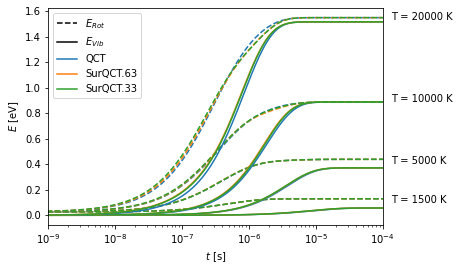

In [25]:
import Plots

Plots.plot_energies(out_dir, System, Data_i, TTranVec)

Taus

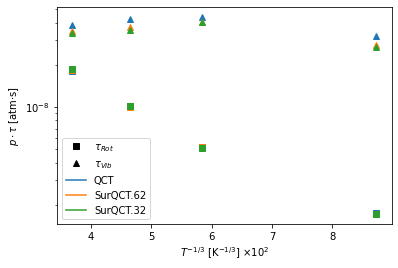

In [19]:
Plots.plot_taus(out_dir, System, Data_i, TTranVec)

Populations

In [ ]:
samples   = [1e-7, 5e-7, 1e-6, 5e-6]
TimeShots = {
    1500:  samples,
    5000:  samples,
    10000: samples,
    20000: samples
}

In [ ]:
# Population plot times
def find_nearest(array, value):
    i = 0
    iStep=[]
    for ivalue in value:
        array = np.asarray(array)
        idx = (np.abs(array - ivalue)).argmin()
        iStep.append(idx)
        i = i+1
    return iStep

def plot_populations(
    Path,
    TempVec,
    TimeShots,
    QCT,
    SurQCT,
    subplots_shape=(1,1),
    figsize_factor=1.5
):
    for iTemp in range(len(TempVec)):
        Temp = TempVec[iTemp]
        QCTStepsVec    = find_nearest(   QCT[Temp]['box'].time, TimeShots[int(Temp)])                                                                                                                                                                               
        SurQCTStepsVec = find_nearest(SurQCT[Temp]['box'].time, TimeShots[int(Temp)])

        fig, ax = plt.subplots(*subplots_shape, sharex=True, figsize=np.array([6.4,4.8])*figsize_factor)
        ax = np.array(ax).reshape(-1)

        for iStep in range(len(TimeShots[int(Temp)])):
            for iMol, Mol in enumerate(System.Molecule):
                cp = ax[iStep].scatter(Mol.EInt - Mol.DissE,    QCT[Temp]['pop'][Mol.Name][   QCTStepsVec[iStep],:]/Mol.g, c='k', s=2, label='QCT')                                                                                                                                
                cp = ax[iStep].scatter(Mol.EInt - Mol.DissE, SurQCT[Temp]['pop'][Mol.Name][SurQCTStepsVec[iStep],:]/Mol.g, c='r', s=2, label='SurQCT', alpha=0.25)
            ax[iStep].set_yscale('log')
            ax[iStep].set_title('$t$ = %.1e s' % TimeShots[int(Temp)][iStep])
            
        fig.add_subplot(111, frame_on=False)
        plt.tick_params(labelcolor='none', which='both', top=False, bottom=False, left=False, right=False)
        plt.xticks([])
        plt.yticks([])
        plt.xlabel('$\epsilon_i$ [eV]', labelpad=30)
        plt.ylabel('$N_i/g_i$ [m$^{-3}$]', labelpad=40)
        
        lines, labels  = ax[0].get_legend_handles_labels()
        plt.legend(lines, labels, frameon=False, markerscale=2.0, ncol=1, bbox_to_anchor=(1., 1.), handletextpad=0.1)
        plt.savefig(Path + f'/Pop_T{Temp}K.pdf', bbox_inches="tight")
        

In [ ]:
plot_populations(out_dir, TTranVec, TimeShots, QCT, SurQCT, subplots_shape=(2,2))

## 